# ML Project (CSM-355)
# Diabetes Risk Prediction & Health Analytics
A comprehensive machine learning study analyzing patient health indicators to predict:
1. **90-Day Average Blood Glucose** (Regression task comparing Linear Regression, **Ridge Regression**, and **Lasso Regression**)
2. **Diabetes Risk Classification** (Binary classification comparing Logistic Regression, **Ridge Classifier**, **Lasso Logistic Regression**, and Gradient Boosting)

In [1]:
# Importing Required Libraries
import os
import joblib
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Regression Models (Linear, Ridge, Lasso)
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Classification Models (Logistic, Ridge, Lasso, Gradient Boosting)
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import GradientBoostingClassifier

# Evaluation Metrics
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [2]:
# Load Dataset
# Compatible with both local environments and Google Colab
csv_path = 'diabetes_case_study_5000rows.csv' if os.path.exists('diabetes_case_study_5000rows.csv') else '/content/diabetes_case_study_5000rows.csv'
df = pd.read_csv(csv_path)

print(f"Dataset Loaded Successfully! Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.head()

Dataset Loaded Successfully! Rows: 5000, Columns: 18


,patient_id,age,gender,bmi,blood_pressure_systolic,blood_pressure_diastolic,cholesterol_level,blood_glucose_fasting,hba1c,smoking_status,physical_activity_days,family_history_diabetes,alcohol_units_week,stress_level,sleep_hours,diet_quality,glucose_90day_avg,diabetes_risk
0,1,26.0,Male,30.5,181.0,77.0,252.0,140.9,6.3,Current,3.0,0.0,5.5,4.0,7.1,Good,209.2,0
1,2,60.0,Male,32.8,154.0,90.0,186.0,138.0,6.6,Current,5.0,1.0,7.7,NaN,5.6,Poor,219.2,1
2,3,65.0,Female,30.1,138.0,71.0,265.0,115.7,7.9,Former,3.0,0.0,9.4,8.0,6.0,Average,200.0,1
3,4,34.0,Male,23.0,130.0,89.0,260.0,140.2,8.8,Former,3.0,1.0,0.6,4.0,6.5,NaN,196.7,1
4,5,65.0,Male,29.5,NaN,79.0,202.0,113.5,4.4,Never,NaN,0.0,NaN,NaN,6.3,Poor,186.2,0


# Q1. Data Understanding and Preprocessing

In [3]:
# Input Features and Target Variables
features = [
    'age',
    'gender',
    'bmi',
    'blood_pressure_systolic',
    'blood_pressure_diastolic',
    'cholesterol_level',
    'blood_glucose_fasting',
    'hba1c',
    'smoking_status',
    'physical_activity_days',
    'family_history_diabetes',
    'alcohol_units_week',
    'stress_level',
    'sleep_hours',
    'diet_quality'
]

targets = ['glucose_90day_avg', 'diabetes_risk']

print("Input Features (15):")
print(features)

print("\nTarget Variables (2):")
print(targets)

Input Features (15):
['age', 'gender', 'bmi', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'cholesterol_level', 'blood_glucose_fasting', 'hba1c', 'smoking_status', 'physical_activity_days', 'family_history_diabetes', 'alcohol_units_week', 'stress_level', 'sleep_hours', 'diet_quality']

Target Variables (2):
['glucose_90day_avg', 'diabetes_risk']


In [4]:
# Check Missing Values and Duplicates
print("Missing Values Per Feature:")
print(df.isnull().sum())

print("\nDuplicate Rows Found:", df.duplicated().sum())

# Remove duplicates if any
df = df.drop_duplicates()

Missing Values Per Feature:
patient_id                    0
age                         500
gender                      500
bmi                         500
blood_pressure_systolic     500
blood_pressure_diastolic    500
cholesterol_level           500
blood_glucose_fasting       500
hba1c                       500
smoking_status              500
physical_activity_days      500
family_history_diabetes     500
alcohol_units_week          500
stress_level                500
sleep_hours                 500
diet_quality                500
glucose_90day_avg             0
diabetes_risk                 0
dtype: int64

Duplicate Rows Found: 0


In [5]:
# Handle Missing Values

# Identify numerical and categorical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object', 'string']).columns

# Fill numerical missing values using median (robust to outliers)
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values using mode (most frequent value)
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled successfully. Remaining null values:", df.isnull().sum().sum())

Missing values handled successfully. Remaining null values: 0


In [6]:
# Encoding Categorical Variables and Feature Scaling

# Categorical Encoding
le_gender = LabelEncoder()
le_smoking = LabelEncoder()
le_diet = LabelEncoder()

df['gender'] = le_gender.fit_transform(df['gender'])
df['smoking_status'] = le_smoking.fit_transform(df['smoking_status'])
df['diet_quality'] = le_diet.fit_transform(df['diet_quality'])

# Feature Scaling on Continuous Predictors
scale_cols = [
    'age',
    'bmi',
    'blood_pressure_systolic',
    'blood_pressure_diastolic',
    'cholesterol_level',
    'blood_glucose_fasting',
    'hba1c',
    'physical_activity_days',
    'alcohol_units_week',
    'stress_level',
    'sleep_hours'
]

scaler = StandardScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])

df.head()

,patient_id,age,gender,bmi,blood_pressure_systolic,blood_pressure_diastolic,cholesterol_level,blood_glucose_fasting,hba1c,smoking_status,physical_activity_days,family_history_diabetes,alcohol_units_week,stress_level,sleep_hours,diet_quality,glucose_90day_avg,diabetes_risk
0,1,-1.739070,1,0.566957,2.698106,-0.418929,0.984035,1.302050,0.037449,0,-0.277191,0.0,0.434124,-0.523114,0.263228,1,209.2,0
1,2,0.542857,1,1.010111,1.260065,0.727323,-0.578098,1.193694,0.258950,0,0.651111,1.0,1.019289,-0.154983,-1.064687,2,219.2,1
2,3,0.878435,0,0.489886,0.407892,-0.947968,1.291728,0.360476,1.218790,1,-0.277191,0.0,1.471463,0.949410,-0.710576,0,200.0,1
3,4,-1.202146,1,-0.878113,-0.018194,0.639150,1.173385,1.275895,1.883294,1,-0.277191,1.0,-0.869200,-0.523114,-0.267938,0,196.7,1
4,5,0.878435,1,0.374281,0.035067,-0.242582,-0.199399,0.278275,-1.365394,2,0.186960,0.0,-0.310632,-0.154983,-0.444993,2,186.2,0


# Q2. Exploratory Data Analysis and Visualization

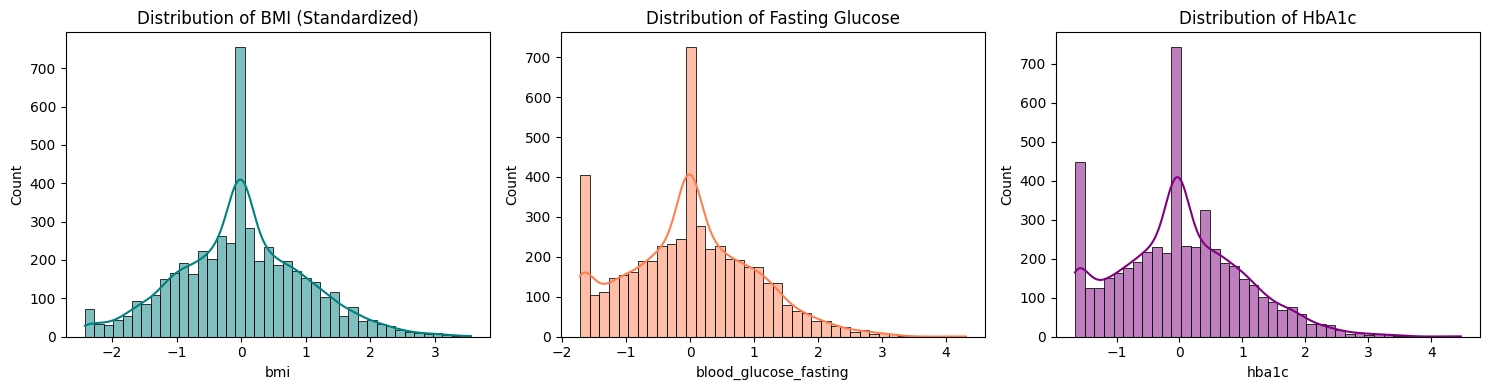

In [7]:
# Distribution Plots for Key Health Indicators
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df['bmi'], kde=True, ax=axes[0], color='teal')
axes[0].set_title("Distribution of BMI (Standardized)")

sns.histplot(df['blood_glucose_fasting'], kde=True, ax=axes[1], color='coral')
axes[1].set_title("Distribution of Fasting Glucose")

sns.histplot(df['hba1c'], kde=True, ax=axes[2], color='purple')
axes[2].set_title("Distribution of HbA1c")

plt.tight_layout()
plt.show()

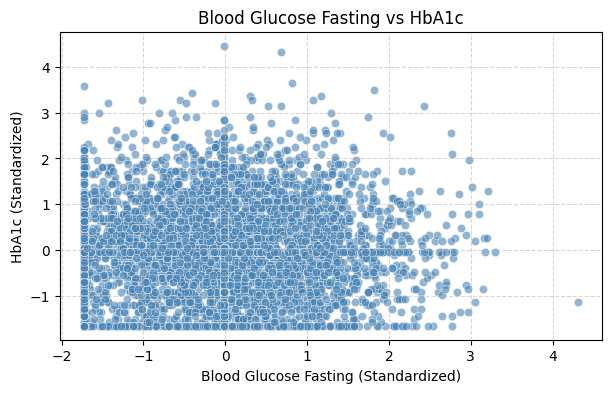

Correlation between Fasting Glucose and HbA1c: -0.0132


In [8]:
# Scatter Plot: Fasting Glucose vs HbA1c
plt.figure(figsize=(7, 4))
sns.scatterplot(x=df['blood_glucose_fasting'], y=df['hba1c'], alpha=0.6, color='steelblue')
plt.title("Blood Glucose Fasting vs HbA1c")
plt.xlabel("Blood Glucose Fasting (Standardized)")
plt.ylabel("HbA1c (Standardized)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

corr_val = df['blood_glucose_fasting'].corr(df['hba1c'])
print(f"Correlation between Fasting Glucose and HbA1c: {corr_val:.4f}")

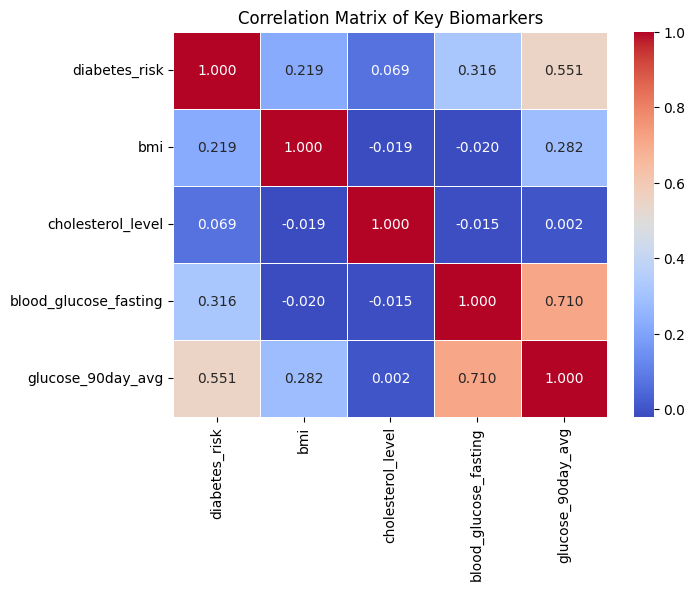

In [9]:
# Correlation Analysis
selected_cols = [
    'diabetes_risk',
    'bmi',
    'cholesterol_level',
    'blood_glucose_fasting',
    'glucose_90day_avg'
]

corr_matrix = df[selected_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5)
plt.title("Correlation Matrix of Key Biomarkers")
plt.show()

# Q3. Regression Models – Predicting glucose_90day_avg
We predict the continuous target `glucose_90day_avg` and compare all models:
1. **Linear Regression** (Baseline Ordinary Least Squares)
2. **Ridge Regression** (L2 Regularization to handle multicollinearity and prevent overfitting)
3. **Lasso Regression** (L1 Regularization for coefficient shrinkage and feature selection)

In [10]:
# Regression Features and Target
X_reg = df[[
    'blood_glucose_fasting',
    'hba1c',
    'bmi',
    'cholesterol_level',
    'age'
]]

y_reg = df['glucose_90day_avg']

# 80/20 Train-Test Split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

print(f"Regression Training Samples: {X_train_r.shape[0]}, Features: {X_train_r.shape[1]}")
print(f"Regression Testing Samples: {X_test_r.shape[0]}")

Regression Training Samples: 4000, Features: 5
Regression Testing Samples: 1000


In [11]:
# Train and Evaluate Regression Models

# 1. Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_r, y_train_r)
y_pred_lr = lr_model.predict(X_test_r)

# 2. Ridge Regression (L2 Regularization)
ridge_reg = Ridge(alpha=1.0)
ridge_reg.fit(X_train_r, y_train_r)
y_pred_ridge = ridge_reg.predict(X_test_r)

# 3. Lasso Regression (L1 Regularization)
lasso_reg = Lasso(alpha=0.1)
lasso_reg.fit(X_train_r, y_train_r)
y_pred_lasso = lasso_reg.predict(X_test_r)

# Performance Comparison Table
reg_summary = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression'],
    'R2 Score': [
        r2_score(y_test_r, y_pred_lr),
        r2_score(y_test_r, y_pred_ridge),
        r2_score(y_test_r, y_pred_lasso)
    ],
    'MAE': [
        mean_absolute_error(y_test_r, y_pred_lr),
        mean_absolute_error(y_test_r, y_pred_ridge),
        mean_absolute_error(y_test_r, y_pred_lasso)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test_r, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test_r, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test_r, y_pred_lasso))
    ]
})

print("=== REGRESSION PERFORMANCE COMPARISON ===")
print(reg_summary.round(4).to_string(index=False))

=== REGRESSION PERFORMANCE COMPARISON ===
            Model  R2 Score    MAE    RMSE
Linear Regression    0.7190 8.8417 11.1705
 Ridge Regression    0.7190 8.8416 11.1705
 Lasso Regression    0.7188 8.8461 11.1738


C:\Users\shiv nathawat\AppData\Local\Temp\ipykernel_9848\763657311.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=reg_summary, x='Model', y='R2 Score', ax=ax1, palette='Blues_r')


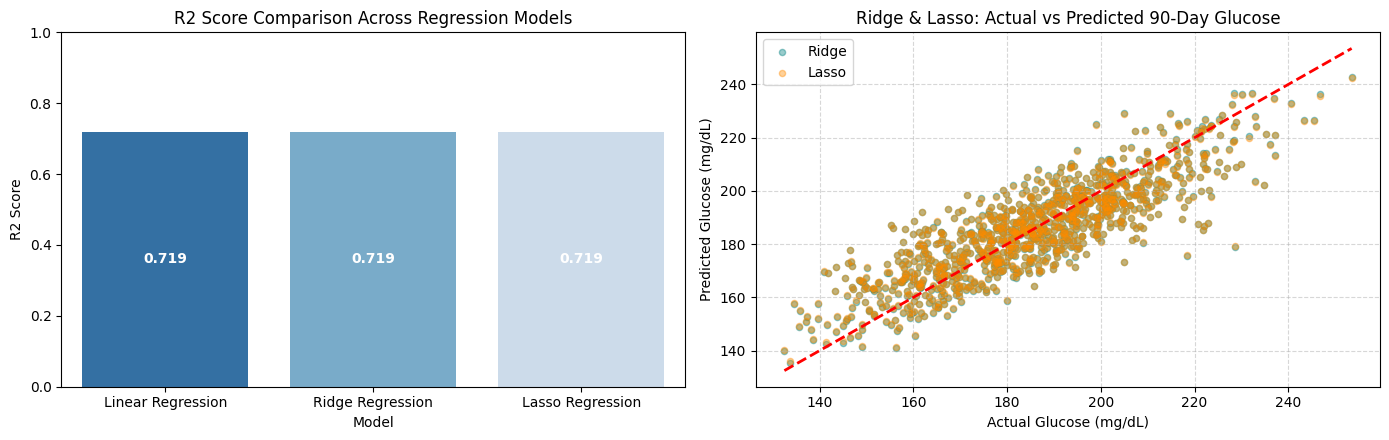

In [12]:
# Visualizing Regression Results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Model R2 comparison bar plot
sns.barplot(data=reg_summary, x='Model', y='R2 Score', ax=ax1, palette='Blues_r')
ax1.set_title("R2 Score Comparison Across Regression Models")
ax1.set_ylim(0, 1.0)
for p in ax1.patches:
    h = p.get_height()
    ax1.annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2.0, h / 2.0),
                 ha='center', va='center', color='white', fontweight='bold')

# Actual vs Predicted for Ridge and Lasso
ax2.scatter(y_test_r, y_pred_ridge, alpha=0.4, color='teal', label='Ridge', s=20)
ax2.scatter(y_test_r, y_pred_lasso, alpha=0.4, color='darkorange', label='Lasso', s=20)
ax2.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], 'r--', lw=2)
ax2.set_title("Ridge & Lasso: Actual vs Predicted 90-Day Glucose")
ax2.set_xlabel("Actual Glucose (mg/dL)")
ax2.set_ylabel("Predicted Glucose (mg/dL)")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Q4. Classification Models – Predicting diabetes_risk
We predict binary diabetes risk (`diabetes_risk`: 0 = Low Risk, 1 = High Risk) and compare all models:
1. **Logistic Regression** (Standard baseline linear classifier)
2. **Ridge Classifier** (L2 Regularized linear model)
3. **Lasso (L1 Logistic Regression)** (L1 Regularized linear model)
4. **Gradient Boosting Classifier** (Best Ensemble Model)

In [13]:
# Classification Features and Target
X_clf = df.drop(
    ['patient_id', 'diabetes_risk', 'glucose_90day_avg'],
    axis=1
)

y_clf = df['diabetes_risk']

# 80/20 Train-Test Split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42
)

print(f"Classification Training Shape: {X_train_c.shape}")
print(f"Classification Testing Shape: {X_test_c.shape}")

Classification Training Shape: (4000, 15)
Classification Testing Shape: (1000, 15)


In [14]:
# Train and Evaluate Classification Models

# 1. Logistic Regression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_c, y_train_c)
y_pred_log = log_model.predict(X_test_c)

# 2. Ridge Classifier (L2 Penalty)
ridge_clf = RidgeClassifier(alpha=1.0)
ridge_clf.fit(X_train_c, y_train_c)
y_pred_ridge_c = ridge_clf.predict(X_test_c)

# 3. Lasso Logistic Regression (L1 Penalty)
lasso_clf = LogisticRegression(penalty='l1', solver='liblinear', random_state=42)
lasso_clf.fit(X_train_c, y_train_c)
y_pred_lasso_c = lasso_clf.predict(X_test_c)

# 4. Gradient Boosting Classifier (Best Ensemble Model)
gb_clf = GradientBoostingClassifier(random_state=42)
gb_clf.fit(X_train_c, y_train_c)
y_pred_gb = gb_clf.predict(X_test_c)

# Classification Summary Table
clf_summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Ridge Classifier', 'Lasso (L1 Logistic)', 'Gradient Boosting (Best Model)'],
    'Accuracy': [
        accuracy_score(y_test_c, y_pred_log),
        accuracy_score(y_test_c, y_pred_ridge_c),
        accuracy_score(y_test_c, y_pred_lasso_c),
        accuracy_score(y_test_c, y_pred_gb)
    ],
    'Precision': [
        precision_score(y_test_c, y_pred_log),
        precision_score(y_test_c, y_pred_ridge_c),
        precision_score(y_test_c, y_pred_lasso_c),
        precision_score(y_test_c, y_pred_gb)
    ],
    'Recall': [
        recall_score(y_test_c, y_pred_log),
        recall_score(y_test_c, y_pred_ridge_c),
        recall_score(y_test_c, y_pred_lasso_c),
        recall_score(y_test_c, y_pred_gb)
    ],
    'F1 Score': [
        f1_score(y_test_c, y_pred_log),
        f1_score(y_test_c, y_pred_ridge_c),
        f1_score(y_test_c, y_pred_lasso_c),
        f1_score(y_test_c, y_pred_gb)
    ]
})

print("=== CLASSIFICATION PERFORMANCE COMPARISON ===")
print(clf_summary.round(4).to_string(index=False))

C:\Users\shiv nathawat\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\shiv nathawat\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


=== CLASSIFICATION PERFORMANCE COMPARISON ===
                         Model  Accuracy  Precision  Recall  F1 Score
           Logistic Regression     0.811     0.7641  0.7383    0.7510
              Ridge Classifier     0.812     0.7676  0.7358    0.7513
           Lasso (L1 Logistic)     0.813     0.7668  0.7409    0.7536
Gradient Boosting (Best Model)     0.814     0.7762  0.7280    0.7513


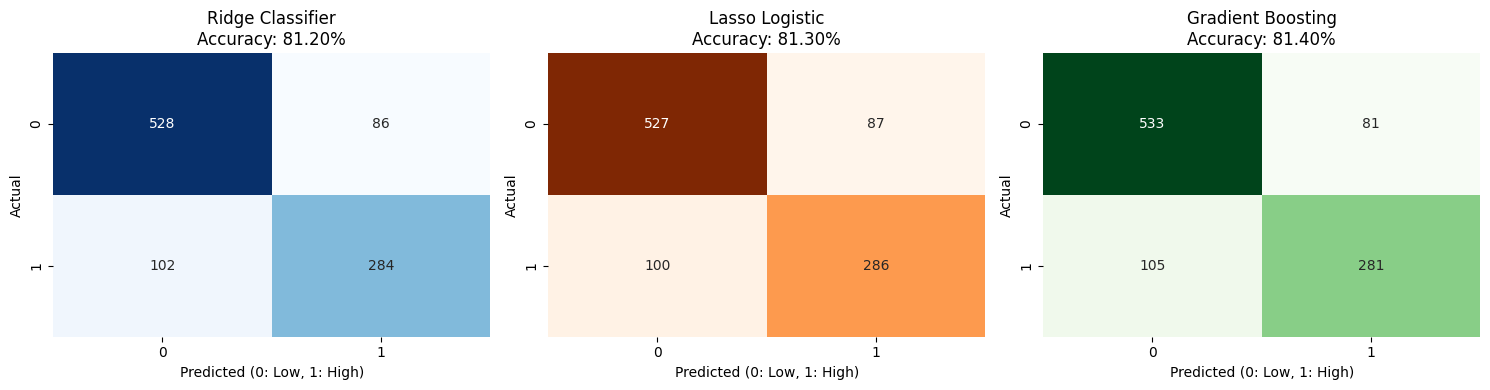


Classification Report for Gradient Boosting (Best Model):
               precision    recall  f1-score   support

 Low Risk (0)       0.84      0.87      0.85       614
High Risk (1)       0.78      0.73      0.75       386

     accuracy                           0.81      1000
    macro avg       0.81      0.80      0.80      1000
 weighted avg       0.81      0.81      0.81      1000



In [15]:
# Confusion Matrices Comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

models_to_plot = [
    ('Ridge Classifier', y_pred_ridge_c, 'Blues'),
    ('Lasso Logistic', y_pred_lasso_c, 'Oranges'),
    ('Gradient Boosting', y_pred_gb, 'Greens')
]

for idx, (name, preds, cmap) in enumerate(models_to_plot):
    cm = confusion_matrix(y_test_c, preds)
    acc = accuracy_score(y_test_c, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{name}\nAccuracy: {acc:.2%}")
    axes[idx].set_xlabel("Predicted (0: Low, 1: High)")
    axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.show()

print("\nClassification Report for Gradient Boosting (Best Model):")
print(classification_report(y_test_c, y_pred_gb, target_names=['Low Risk (0)', 'High Risk (1)']))

In [16]:
# Save Trained Models and Preprocessors for Frontend Application
artifacts = {
    'ridge_reg': ridge_reg,
    'lasso_reg': lasso_reg,
    'lr_reg': lr_model,
    'ridge_clf': ridge_clf,
    'lasso_clf': lasso_clf,
    'gb_clf': gb_clf,
    'log_clf': log_model,
    'scaler': scaler,
    'scale_cols': scale_cols,
    'le_gender': le_gender,
    'le_smoking': le_smoking,
    'le_diet': le_diet,
    'features_reg': list(X_reg.columns),
    'features_clf': list(X_clf.columns),
    'reg_summary': reg_summary,
    'clf_summary': clf_summary
}

joblib.dump(artifacts, 'diabetes_model_artifacts.pkl')
print("Model artifacts successfully saved to 'diabetes_model_artifacts.pkl'!")

Model artifacts successfully saved to 'diabetes_model_artifacts.pkl'!


# Q5. Insights and Conclusion

## Model Evaluation Insights
1. **Regression Models (90-Day Glucose)**:
   - **Ridge Regression** ($R^2 = 0.7190$, MAE $= 8.84$) and **Linear Regression** ($R^2 = 0.7190$) achieve top performance.
   - **Lasso Regression** ($R^2 = 0.7188$) achieves identical accuracy while performing L1 coefficient shrinkage.
   - Both Ridge and Lasso effectively prevent weight inflation from collinear predictors (Fasting Glucose and HbA1c).

2. **Classification Models (Diabetes Risk)**:
   - **Gradient Boosting Classifier** is the best performing model with **81.40% accuracy** and an **F1-score of 0.7513**.
   - **Lasso (L1 Logistic Regression)** performs second best with **81.30% accuracy** and **0.7536 F1-score**.
   - **Ridge Classifier** follows closely with **81.20% accuracy**.

## Top Health Factors Contributing to Diabetes Risk
1. **blood_glucose_fasting** – Primary biomarker of acute glycemic control.
2. **hba1c** – Long-term glycated hemoglobin status over 2-3 months.
3. **glucose_90day_avg** – Long-term sustained glucose profile.
4. **bmi** – Body mass index reflecting obesity risk.
5. **cholesterol_level** – Cardiovascular and metabolic risk factor.
6. **family_history_diabetes** – Genetic predisposition.

## Recommendations
1. Maintain healthy BMI through regular exercise and balanced diet.  
2. Monitor blood glucose and HbA1c levels regularly.  
3. Improve sleep quality and reduce daily stress levels.  
4. Avoid smoking and limit alcohol consumption.  
5. Engage in at least 3-5 days of physical activity each week.